# Slow Momentum with Fast Reversion - Five-asset study

SP: S&P 500 day-session futures; TY: US 10-year Treasury-note futures; BN: British-pound futures; ZG: gold futures; ZU: crude-oil futures.

Thirty author-source model/window searches and 1,500 candidate fits are complete. Core LSTM, Sharpe objective, feature formatting and GPflow CPD use the pinned author repository with recorded compatibility/runtime adaptations.

**Run All displays the completed aggregate results.** Training is disabled by default. Paper figures refer to 50 Pinnacle instruments; this experiment uses five WRDS instruments and is not a matched-universe numerical reproduction.


In [1]:
from pathlib import Path
import sys, json
import pandas as pd
import yaml
from IPython.display import display, Markdown
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src/momentum_lab').is_dir())
sys.path.insert(0,str(ROOT/'src'))
CONFIG_PATH = 'configs/author_five_assets.yaml'
config = yaml.safe_load((ROOT/CONFIG_PATH).read_text(encoding='utf-8'))
assert config['tickers'] == ['SP','TY','BN','ZG','ZU']
display(pd.read_csv(ROOT/'configs/universe.csv').set_index('ticker').loc[config['tickers'],['description','asset_class','published_first_test']])


,description,asset_class,published_first_test
ticker,,,
SP,S&P500 day session,Equities,1995
TY,10yr T-note composite,Fixed Income,1995
BN,British pound composite,FX,1995
ZG,Gold electronic,Commodities,1995
ZU,Crude oil electronic,Commodities,1995


## Completed results or a new experiment

The default reads committed tables and figures under report/. No WRDS account, fitted weights or GPU is needed to view the results. Set RUN_EXPERIMENT=True only to run the full author-source pipeline after preparing licensed inputs and the validated runtime described in docs/REPLICATION.md.

The completed protocol uses five test periods: 1995-1999, 2000-2004, 2005-2009, 2010-2014 and 2015-2020 inclusive. The final period spans six calendar years. A strict 1995-2019 sensitivity is also reported, making the paper's endpoint ambiguity explicit. All searches retain 50 candidates, 300-epoch cap, 25-epoch patience, a 63-step sequence and per-asset 90/10 train/validation splits.


In [2]:
RUN_EXPERIMENT = False
if RUN_EXPERIMENT:
    import importlib
    import momentum_lab.author_progress as progress
    import momentum_lab.author_notebook as runner
    importlib.reload(progress)
    importlib.reload(runner)
    runner.run_author(config_path=CONFIG_PATH)
else:
    print('Completed five-asset results; training disabled.')


Completed five-asset results; training disabled.


## Completion evidence

The manifest is generated only after all requested searches finish. Smoke tests do not count as experiment results.


In [3]:
manifest_path = ROOT/('report/author_five_assets/execution_manifest.json' if RUN_EXPERIMENT else 'report/execution_manifest.json')
manifest = json.loads(manifest_path.read_text())
assert manifest['completed_experiments'] == manifest['expected_experiments'] == 30
assert manifest['completed_trials'] == 1500
assert set(manifest['instruments']) == set(config['tickers'])
print('Completed searches:',manifest['completed_experiments'],'Candidate fits:',manifest['completed_trials'])
print(manifest['comparison_scope'])
T = ROOT/('results/author_five_assets/tables' if RUN_EXPERIMENT else 'report/tables/replication')


Completed searches: 30 Candidate fits: 1500
Five-instrument subset validation against a 50-instrument published reference; not a matched-universe reproduction.


## Exhibit 3 — raw signal performance using author metric functions

In [4]:
exhibit3 = pd.read_csv(T/'exhibit_3.csv').set_index('strategy')
display(exhibit3)

,annual_return,annual_volatility,sharpe_ratio,downside_risk,sortino_ratio,max_drawdown,calmar_ratio,perc_pos_return,profit_loss_ratio
strategy,,,,,,,,,
LSTM,0.032356,0.045644,0.588924,0.031653,0.858945,0.073019,0.520319,0.521870,1.014206
LSTM-CPD-10,0.017341,0.044257,0.374773,0.031326,0.537336,0.083936,0.213720,0.517800,0.994842
LSTM-CPD-126,0.025519,0.037299,0.629225,0.025532,0.930054,0.068258,0.466954,0.521404,1.023114
LSTM-CPD-21,0.027199,0.049822,0.551295,0.034900,0.815045,0.103793,0.421905,0.525427,0.993588
LSTM-CPD-252,0.027357,0.053793,0.582952,0.037745,0.855572,0.109752,0.386529,0.525876,0.997218
LSTM-CPD-63,0.022337,0.038781,0.521017,0.026864,0.767048,0.075490,0.373082,0.521037,1.005854
LSTM-CPD-Optimised,0.021348,0.046109,0.518250,0.032066,0.780569,0.109322,0.395338,0.517364,1.019605
Long Only,0.056603,0.076570,0.767940,0.053468,1.118038,0.123680,0.612170,0.532270,0.997867
MACD,0.035245,0.056105,0.649217,0.039042,0.936461,0.082674,0.445018,0.532103,0.981270


## Five-instrument results versus the published reference

The left column is this five-instrument WRDS experiment. The reference column is the paper's 50-instrument Pinnacle portfolio. Interpret direction and relative CPD improvements; a numerical gap cannot be attributed to implementation alone because the universes differ.


,Five-asset WRDS Sharpe,Paper 50-asset Pinnacle Sharpe
strategy,,
LSTM,0.588924,1.62
LSTM-CPD-10,0.374773,1.77
LSTM-CPD-126,0.629225,1.75
LSTM-CPD-21,0.551295,2.04
LSTM-CPD-252,0.582952,1.45
LSTM-CPD-63,0.521017,2.08
LSTM-CPD-Optimised,0.518250,2.16
Long Only,0.767940,0.44
MACD,0.649217,0.77


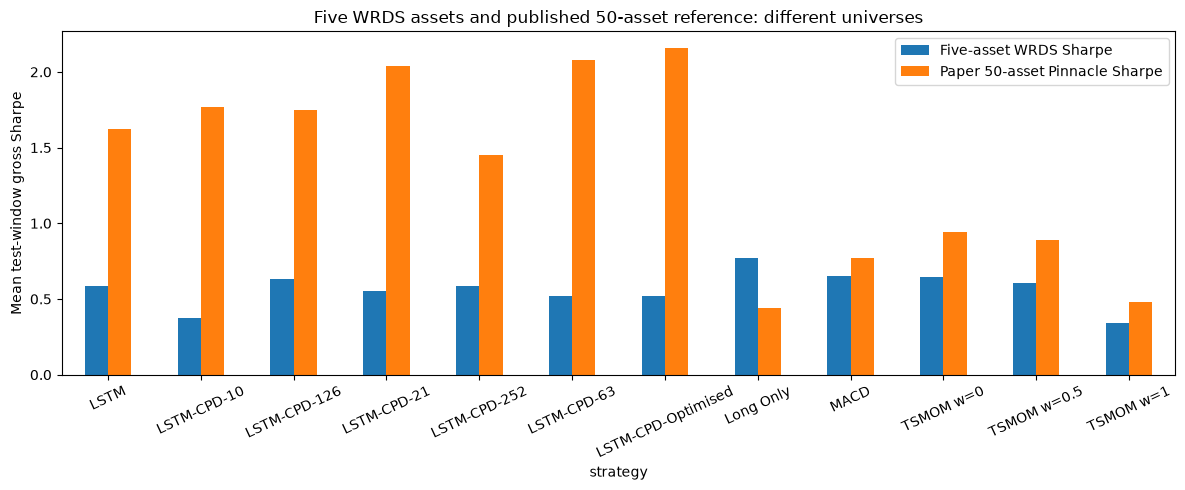

In [5]:
published = pd.read_csv(T/'published_reference.csv')
published = published[published.exhibit.eq(3)].set_index('strategy')
comparison = exhibit3[['sharpe_ratio']].rename(columns={'sharpe_ratio':'Five-asset WRDS Sharpe'}).join(published[['sharpe']].rename(columns={'sharpe':'Paper 50-asset Pinnacle Sharpe'}))
display(comparison)
import matplotlib.pyplot as plt
ax = comparison.plot.bar(figsize=(12,5),rot=25)
ax.set_title('Five WRDS assets and published 50-asset reference: different universes')
ax.set_ylabel('Mean test-window gross Sharpe')
ax.figure.tight_layout()
plt.show()


## Exhibit 4 — ex-post 15% mean volatility rescaling

Returns are rescaled and metrics recomputed using the authors' aggregation convention.
This ex-post scaling is for comparison with the paper, not an implementable ex-ante risk forecast.


In [6]:
display(pd.read_csv(T/'exhibit_4.csv').set_index('strategy'))

,annual_return,annual_volatility,sharpe_ratio,downside_risk,sortino_ratio,max_drawdown,calmar_ratio,perc_pos_return,profit_loss_ratio
strategy,,,,,,,,,
LSTM,0.106868,0.15,0.588924,0.104020,0.858945,0.221400,0.553313,0.521870,1.014206
LSTM-CPD-10,0.050440,0.15,0.374773,0.106172,0.537336,0.265679,0.196125,0.517800,0.994842
LSTM-CPD-126,0.100556,0.15,0.629225,0.102677,0.930054,0.253474,0.492288,0.521404,1.023114
LSTM-CPD-21,0.079255,0.15,0.551295,0.105075,0.815045,0.268055,0.440239,0.525427,0.993588
LSTM-CPD-252,0.070883,0.15,0.582952,0.105250,0.855572,0.281323,0.390242,0.525876,0.997218
LSTM-CPD-63,0.083293,0.15,0.521017,0.103905,0.767048,0.267151,0.390139,0.521037,1.005854
LSTM-CPD-Optimised,0.065242,0.15,0.518250,0.104315,0.780569,0.300600,0.407078,0.517364,1.019605
Long Only,0.108387,0.15,0.767940,0.104743,1.118038,0.230302,0.626366,0.532270,0.997867
MACD,0.089744,0.15,0.649217,0.104381,0.936461,0.211500,0.444573,0.532103,0.981270


## Transaction costs

The first table applies the author cost function. The second evaluates raw same-contract returns with both futures-roll legs charged. These are separate sensitivities; they do not alter the training objective or gross paper comparison. Fixed basis points are scenarios, not measured market impact.


In [7]:
author_costs = pd.read_csv(T/'author_transaction_costs.csv')
roll_costs = pd.read_csv(T/('professor_roll_cost_sensitivity.csv' if RUN_EXPERIMENT else 'roll_cost_sensitivity.csv'))
display(author_costs.groupby(['strategy','bps']).sharpe_ratio.mean().unstack())
display(roll_costs.groupby(['strategy','bps']).sharpe_ratio.mean().unstack())


bps,0.5,1.0,2.0,2.5,3.0,5.0
strategy,,,,,,
LSTM,0.532972,0.477020,0.365122,0.309179,0.253241,0.029577
LSTM-CPD-10,0.303625,0.232470,0.090149,0.018990,-0.052163,-0.336652
LSTM-CPD-126,0.534210,0.439210,0.249275,0.154348,0.059456,-0.319689
LSTM-CPD-21,0.498086,0.444876,0.338461,0.285257,0.232058,0.019338
LSTM-CPD-252,0.523216,0.463479,0.344012,0.284288,0.224573,-0.014128
LSTM-CPD-63,0.452143,0.383287,0.245639,0.176852,0.108093,-0.166612
LSTM-CPD-Optimised,0.432791,0.347342,0.176490,0.091095,0.005726,-0.335401
Long Only,0.763597,0.759254,0.750569,0.746227,0.741884,0.724514
MACD,0.638506,0.627795,0.606373,0.595661,0.584950,0.542102


bps,0.0,0.5,1.0,2.0,2.5,3.0,5.0
strategy,,,,,,,
LSTM,0.588924,0.523591,0.458265,0.327644,0.262356,0.197086,-0.063760
LSTM-CPD-10,0.374773,0.294058,0.213339,0.051911,-0.028788,-0.109470,-0.431928
LSTM-CPD-126,0.629225,0.525375,0.421546,0.213977,0.110250,0.006570,-0.407551
LSTM-CPD-21,0.551295,0.487724,0.424161,0.297069,0.233545,0.170041,-0.083728
LSTM-CPD-252,0.582952,0.512105,0.441257,0.299578,0.228756,0.157951,-0.125004
LSTM-CPD-63,0.521017,0.443229,0.365463,0.210009,0.132330,0.054689,-0.255428
LSTM-CPD-Optimised,0.518250,0.423456,0.328685,0.139231,0.044561,-0.050063,-0.427981
Long Only,0.767940,0.751146,0.734350,0.700751,0.683948,0.667143,0.599918
MACD,0.649217,0.627311,0.605400,0.561566,0.539643,0.517718,0.430000


## Selected CPD windows and source audit

CPD windows are selected using pre-test validation performance only, never by choosing the highest test Sharpe after observing outcomes.


In [8]:
display(pd.read_csv(T/'selected_cpd_windows.csv'))
display(pd.read_csv(T/'feature_revalidation.csv').groupby('column').max_abs_difference.max())
print('Upstream commit:', manifest['author_commit'])

,fold,strategy,validation_sharpe
0,1995,LSTM-CPD-63,4.263380
1,2000,LSTM-CPD-63,3.211779
2,2005,LSTM-CPD-126,2.702323
3,2010,LSTM-CPD-126,1.409920
4,2015,LSTM-CPD-21,2.015543


column
daily_vol                0.000000e+00
macd_16_48               8.517631e-13
macd_32_96               4.255263e-12
macd_8_24                0.000000e+00
norm_annual_return       0.000000e+00
norm_biannual_return     0.000000e+00
norm_daily_return        0.000000e+00
norm_monthly_return      0.000000e+00
norm_quarterly_return    0.000000e+00
target_returns           0.000000e+00
Name: max_abs_difference, dtype: float64

Upstream commit: e0352cb0bdbf8045accb1bf1a5705ae0cb9ea624


## Results and interpretation

LSTM gross Sharpe is 0.589; validation-selected CPD-LSTM is 0.518. Fixed 126-day CPD achieves 0.629, but retrospective selection of that test result would not reproduce the validation-selected method. The paper reports LSTM 1.62 and optimized CPD 2.16 on a different 50-instrument Pinnacle portfolio.

The five-asset result does not recover the reported CPD improvement. Universe size, price/roll construction, sample coverage, framework compatibility, random-search realization and the explicit date-boundary convention differ. Their individual effects cannot be identified from this experiment alone. See report/RESULTS.md for the complete comparison and limitations.
